> **第二部分的历史方法记录｜归档说明（2026-10-28）**
> 本文保留当时的方法、代码与输出；“尚未拟合”等进度句只描述该阶段。最新结果见 [H0–H3 综合 Notebook](matching_h0_h3_results.ipynb) 与 [当前 README](README_zh.md)。第三部分尚未正式分析。
> 研究日志不是一键复现入口；尤其 observation_recovery 含昂贵采样和本地中间文件依赖，不要直接 Run All。

# Matching：H0–H3 前向生成模拟

本 Notebook 检查固定生成参数下的可观测预测差异，尚不进行参数恢复、模型恢复或真实数据拟合。使用实际 42 名被试的刺激安排，每个模拟数据集包含 25,200 个试次。原始结果文件只读；全部表格和图片保存在本 Notebook。

## 本轮固定规格

上边界为 Match，刺激方向 s 在 Match 时为 +1，在 Mismatch 时为 −1。有效漂移为 μ = s × v × exp(λ) + dc；Match 的 λ = 0。z 是相对起点，绝对起点为 a × z；t 为非决策时间；扩散噪声尺度固定为 1。

- H0：Good-self 与 Bad-self 的 v、dc 均相同。
- H1：仅 v 在两条件间变化。
- H2：仅 dc 在两条件间变化。
- H3：v、dc 均变化。

Self 的基准 v 为历史 M4 两个条件均值的几何平均，基准 dc 为算术平均。目标效应分别为 log(v_GS/v_BS) 和 dc_GS−dc_BS；Other 条件参数在四模型间相同。所有模型共享同一 a、t、z 及观察规则。这里的 M4 数值仅为生成锚点，不传播其后验不确定性，也不用于比较模型优劣。

四个情景为：S0 同质被试、无关系难度；S1 加入固定关系难度；S2 再加入假设的个体差异；S3 在 S2 基础上将截止代理值缩短 1/60 秒。Mismatch 的 λ 按仅身份不同、仅道德属性不同、两者均不同分别设为 −0.20、−0.05、0.25，和为零；这些值不是从关系正确率拟合而来。S2/S3 的个体扰动标准差依次为 log(a) 0.10、log(t) 0.08、log(v) 0.15、logit(z) 0.20、dc 0.10，固定一次后跨模型与重复共用。这些是生成假设，不是推断先验。

每个情景每模型运行 20 次独立试次噪声重复，属于有限前向检查；个体参数不在重复间重抽。跨模型共用随机数以降低对比的模拟噪声。未覆盖弱效应、反向效应或完整参数空间。

## 观察机制

每名被试无反应记录的 RT 中位数作为截止时间代理；它不是已验证的精确截止值。超过截止时仍未触边的概率质量作为超时，不将实际 649 条无反应记录固定到模拟中。不模拟离群反应、漏按或非法按键。24 条其他无效记录仍保留其刺激安排，但其无效原因不由本模型解释。

使用无离群 Wiener 联合选择–RT 密度的数值积分与逆 CDF 抽样，不对截止前的响应概率重新归一化。步长 0.0005 秒，并用减半步长核验；这不是 Euler 轨迹模拟。超时 RT 设为缺失值，不把截止时间当作决策 RT。


## 本轮结果

已完成四情景 × 四模型 × 20 次重复，共 320 个完整数据集（8,064,000 个模拟试次）。1,557 个不同参数组合的 CDF 在步长减半时最大差异为 0.00000573；无截止选择概率与解析解一致，抽样概率、截止和固定种子复现检查通过。

代表情景 S2 中，Good-self 相对 Bad-self 的平均正确 RT 差异如下；负值表示更快。

| 生成模型 | Match | Mismatch |
|---|---:|---:|
| H0 | −0.95 ms | +0.42 ms |
| H1：仅 v | −23.61 ms | −23.59 ms |
| H2：仅 dc | −20.90 ms | +19.72 ms |
| H3：v 与 dc | −42.24 ms | −3.99 ms |
| 观测数据，同一汇总口径 | −82.93 ms | −14.54 ms |

这些差异说明所选参数产生了不同预测，但没有证明模型能够被可靠恢复。H3 未同时重现真实 RT 差异、超时比例和快速反应偏向。S2 四模型预测平均超时比例约 7.22%–7.33%，高于观测 649/25,200 = 2.58%。该偏差说明历史参数锚点不能直接移植为已验证的截止模型；它本身不能否定纯超时机制。

CBF 中，观测的 Good-self Match 偏向主要集中在快速响应；本轮 H3 的差异反而在中、慢响应较大。这个不一致需要后续检查，不能由本次模拟断言由 z 导致。部分模拟分位×刺激单元最少仅 2 个响应，CBF 尾部形状仍需重复与稀疏单元敏感性检查。

这里观测 RT 包含所有合法正确响应，未沿用历史行为表剔除 RT≤0.2 秒的规则，因此与前期 Notebook 的历史复现汇总存在小幅差异。假设的标签难度和个体变异没有经过拟合；不能以本图中哪个点更接近观测线来选择模型。


In [1]:
from pathlib import Path
import hashlib, json, platform, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.integrate import cumulative_trapezoid
from scipy.special import expit, logit
import hddm
from IPython.display import display

ROOT = Path.cwd()
if not (ROOT / 'Data/matching_input.csv').exists():
    ROOT = ROOT / '02_reanalysis_2026'
assert (ROOT / 'Data/matching_input.csv').exists(), 'Run from repository root or Part II'
REPO = ROOT.parent
paths = {
 'raw': REPO/'01_reproduction_2020/Data/raw/confirm/MS_rep_matchingTask_raw.csv',
 'subjects': REPO/'01_reproduction_2020/Output/behavior/confirm/MS_match_behav_wide.csv',
 'parameters': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_parameter_contrasts.csv',
 'diagnostics': ROOT/'Output/hddm/matching/m4/final/diagnostics/matching_precise_diagnostics.csv'}
hashes = {k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}
print(json.dumps({'sources':hashes,'python':platform.python_version(),'hddm':hddm.__version__,
                  'numpy':np.__version__,'pandas':pd.__version__,'seed':2026102401},indent=2))
raw = pd.read_csv(paths['raw'],keep_default_na=False)
subjects = sorted(pd.read_csv(paths['subjects']).Subject.unique())
d = raw[raw.Subject.isin(subjects)].copy().reset_index(drop=True)
assert len(subjects)==42 and len(d)==25200 and d.groupby('Subject').size().eq(600).all()
d['condition'] = d.Morality+'_'+d.Identity
d['stim'] = (d.Match=='match').astype(int)
mapping={'moralSelf':('Good','Self'),'immoralSelf':('Bad','Self'),
         'moralOther':('Good','Other'),'immoralOther':('Bad','Other')}
def relation(row):
    x,y=mapping[row.Shape],mapping[row.Label]
    return 'same' if x==y else ('identity_only' if x[0]==y[0] else ('valence_only' if x[1]==y[1] else 'both'))
d['relation']=d.apply(relation,axis=1)
assert ((d.relation=='same')==d.stim.eq(1)).all()
deadlines=d[d.ACC.eq(-1)].groupby('Subject').RT.median()
assert len(deadlines)==42
p=pd.read_csv(paths['parameters']).set_index('parameter')['mean']
diag=pd.read_csv(paths['diagnostics'],index_col=0)
A,T,Z=float(diag.loc['a','mean']),float(diag.loc['t','mean']),float(p['z'])
V0=np.sqrt(p['v(Self.Good)']*p['v(Self.Bad)'])
D0=(p['dc(Self.Good)']+p['dc(Self.Bad)'])/2
BV=np.log(p['v(Self.Good)']/p['v(Self.Bad)'])
BD=p['dc(Self.Good)']-p['dc(Self.Bad)']
MODELS=['H0','H1','H2','H3']; SCENARIOS=['S0','S1','S2','S3']; REPEATS=20
conditions=['Good_Self','Bad_Self','Good_Other','Bad_Other']
effects=pd.DataFrame([[m, BV if m in ['H1','H3'] else 0,BD if m in ['H2','H3'] else 0] for m in MODELS],columns=['model','beta_log_v','beta_dc'])
display(effects)
print('a,t,z:',A,T,Z,'deadline proxy range:',deadlines.min(),deadlines.max())


{
  "sources": {
    "raw": "ee0da77b217f5f4719e41efa7adae207b1f1deacd87ee86acb1bd50ff528afbc",
    "subjects": "2ad1d92d3828f474efd78956068320d49705b9a2bc84f51a5823cec20042e1d8",
    "parameters": "81e468b380e44af75809fbc901c24a818ed7c929b4bf23ce72e1707a48e5796a",
    "diagnostics": "af5a5eed9f17cb5a4bbdcf8ecfd4a032266d879209e0622d8f1e4c23f0541025"
  },
  "python": "3.9.13",
  "hddm": "1.0.1RC",
  "numpy": "1.23.3",
  "pandas": "2.0.1",
  "seed": 2026102401
}


,model,beta_log_v,beta_dc
0,H0,0.000000,0.000000
1,H1,0.358023,0.000000
2,H2,0.000000,0.600222
3,H3,0.358023,0.600222


a,t,z: 1.2242069382093794 0.464327964026853 0.5680916892738427 deadline proxy range: 1.017 1.1831


In [2]:
# Fixed subject effects and density kernels; no MCMC or model fitting.
rng=np.random.default_rng(2026102401)
deviations=dict(zip(subjects,rng.normal(size=(42,5))*[.10,.08,.15,.20,.10]))
groups=list(d.groupby(['Subject','condition','stim','relation'],sort=True).indices.items())
LAM={'same':0,'identity_only':-.20,'valence_only':-.05,'both':.25}
def parameters(key,model,scenario):
    subject,condition,stim,rel=key
    dv=deviations[subject] if scenario in ['S2','S3'] else np.zeros(5)
    a,t,z=A*np.exp(dv[0]),T*np.exp(dv[1]),expit(logit(Z)+dv[3])
    val,ident=condition.split('_')
    if ident=='Self':
        x=.5 if val=='Good' else -.5
        v=V0*np.exp((BV*x if model in ['H1','H3'] else 0)+dv[2])
        dc=D0+(BD*x if model in ['H2','H3'] else 0)+dv[4]
    else:
        v=p[f'v(Other.{val})']*np.exp(dv[2]); dc=p[f'dc(Other.{val})']+dv[4]
    mu=(2*stim-1)*v*np.exp(LAM[rel] if scenario!='S0' else 0)+dc
    deadline=float(deadlines[subject])-(1/60 if scenario=='S3' else 0)
    assert 0<t<deadline and a>0 and 0<z<1
    return (float(mu),float(a),float(z),float(t)),deadline

def kernel(par,dt=.0005,end=1.3):
    mu,a,z,t=par
    grid=np.arange(0,end+dt/2,dt)
    density=[]
    for sign in [1,-1]:
        f=hddm.wfpt.pdf_array(sign*grid,mu,0.,a,z,0.,t,0.,err=1e-8)
        assert np.isfinite(f).all() and (f>=0).all()
        density.append(cumulative_trapezoid(f,grid,initial=0))
    cdf=np.asarray(density)
    assert (np.diff(cdf,axis=1)>=-1e-14).all() and cdf[:,-1].sum()<=1+1e-6
    return grid,cdf

cache={}; kernels={}; numerical_errors=[]
for scenario in SCENARIOS:
    for model in MODELS:
        prepared=[]
        for key,idx in groups:
            par,deadline=parameters(key,model,scenario)
            if par not in cache:
                coarse=kernel(par); fine=kernel(par,dt=.00025)
                error=np.max(np.abs(coarse[1]-fine[1][:,::2]))
                numerical_errors.append(error); cache[par]=coarse
            grid,cdf=cache[par]
            prob=np.array([np.interp(deadline,grid,c) for c in cdf])
            assert prob.sum()<=1+1e-6
            prepared.append((idx,deadline,grid,cdf,prob))
        kernels[scenario,model]=prepared
assert max(numerical_errors)<1e-4
print('Unique kernels:',len(cache),'maximum CDF step-halving difference:',max(numerical_errors))

def draw(prepared,u):
    choice=np.full(len(d),-1,dtype=int); rt=np.full(len(d),np.nan)
    for idx,deadline,grid,cdf,prob in prepared:
        x=u[idx]; up=x<prob[0]; low=(x>=prob[0])&(x<prob.sum())
        for mask,channel,offset,response in [(up,0,0,1),(low,1,prob[0],0)]:
            ii=idx[mask]; choice[ii]=response
            rt[ii]=np.interp(x[mask]-offset,cdf[channel],grid)
            assert (rt[ii]<=deadline+1e-10).all()
    return choice,rt

# Independent analytic infinite-horizon choice probability and symmetry checks.
checks=[]
for mu in [-2.,0.,2.]:
    grid,cdf=kernel((mu,A,.5,T),dt=.00025,end=10)
    analytic=.5 if mu==0 else -np.expm1(-2*mu*A*.5)/-np.expm1(-2*mu*A)
    checks.append([mu,cdf[0,-1],analytic,cdf[:,-1].sum()])
assert max(abs(x[1]-x[2]) for x in checks)<1e-5
assert max(abs(x[3]-1) for x in checks)<1e-5
display(pd.DataFrame(checks,columns=['mu','integrated_P_upper','analytic_P_upper','total_mass']))
# Empirical sampling check at one representative kernel.
idx,D,g,c,F=kernels['S2','H3'][0]
u=np.random.default_rng(71).random(200000)
emp=np.array([(u<F[0]).mean(),((u>=F[0])&(u<F.sum())).mean(),(u>=F.sum()).mean()])
expected=np.r_[F,1-F.sum()]
assert np.all(abs(emp-expected)<5*np.sqrt(expected*(1-expected)/len(u))+1/len(u))
print('Sampling probabilities:',emp,'expected:',expected)
u=np.random.default_rng(12).random(len(d))
x=draw(kernels['S0','H0'],u); y=draw(kernels['S0','H0'],u)
assert np.array_equal(x[0],y[0]) and np.allclose(x[1],y[1],equal_nan=True)
print('Numerical integration, probability, deadline and reproducibility checks passed.')


Unique kernels: 1557 maximum CDF step-halving difference: 5.729597174590484e-06


,mu,integrated_P_upper,analytic_P_upper,total_mass
0,-2.0,0.079555,0.079555,1.0
1,0.0,0.500000,0.500000,1.0
2,2.0,0.920445,0.920445,1.0


Sampling probabilities: [0.066525 0.738905 0.19457 ] expected: [0.0670222  0.73803972 0.19493808]
Numerical integration, probability, deadline and reproducibility checks passed.


## 汇总规则

先计算被试内各条件指标，再对被试等权平均。正确率同时报告全试次分母和已响应分母；RT 只使用对应正确或错误响应。RT 单位为秒。CBF 在每名被试、每个关联条件内按已响应 RT 分三等份，分别计算两种刺激下的 Match 选择比例，再取等权平均 B；分位区间不是各条件共享的绝对 RT 区间。缺少某刺激的分位单元不补值，并记录有效人数。

各次重复使用同一组个体参数与截止代理值；重复间区间仅反映试次抽样变异，不代表总体参数不确定性，也不是可信区间。观测数据与模拟使用相同汇总规则；观测数据的无效按键不会被强行归为超时。


In [3]:
base=d[['Subject','condition','stim','relation']].copy()
stim=d.stim.to_numpy()
cell_groups=list(base.groupby(['Subject','condition','stim'],sort=True).indices.items())
rel_groups=list(base[base.stim.eq(0)].groupby(['Subject','condition','relation']).groups.items())
cb_groups=list(base.groupby(['Subject','condition']).indices.items())
def summarize(choice,rt,timeout):
    rows=[]; relation_rows=[]; cb=[]
    for (sub,cond,s),ix in cell_groups:
        resp=choice[ix]>=0; correct=choice[ix]==s
        rec={'Subject':sub,'condition':cond,'stim':s,'accuracy_all':correct.mean(),
             'accuracy_responded':correct[resp].mean() if resp.any() else np.nan,
             'P_match':(choice[ix][resp]==1).mean() if resp.any() else np.nan,
             'timeout':timeout[ix].mean(),'n_responded':resp.sum()}
        for label,mask in [('correct',correct),('error',resp&~correct)]:
            vals=rt[ix][mask]; rec['n_'+label]=len(vals)
            rec[label+'_mean']=np.mean(vals) if len(vals) else np.nan
            for q in [.1,.5,.9]: rec[label+'_q'+str(int(q*100))]=np.quantile(vals,q) if len(vals) else np.nan
        rows.append(rec)
    for (sub,cond,rel),ix in rel_groups:
        ix=np.asarray(ix); correct=choice[ix]==0
        relation_rows.append({'Subject':sub,'condition':cond,'relation':rel,'accuracy_all':correct.mean(),
                             'timeout':timeout[ix].mean(),'correct_mean':np.mean(rt[ix][correct]) if correct.any() else np.nan})
    for (sub,cond),ix in cb_groups:
        ix=ix[choice[ix]>=0]
        if len(ix)<3: continue
        bins=pd.qcut(rt[ix],3,labels=False,duplicates='drop')
        for b in range(3):
            selected=ix[np.asarray(bins)==b]
            parts=[selected[stim[selected]==s] for s in [0,1]]
            cb.append({'Subject':sub,'condition':cond,'bin':b+1,
                       'B':np.mean([(choice[j]==1).mean() for j in parts]) if all(len(j)>0 for j in parts) else np.nan,
                       'min_cell_n':min(map(len,parts))})
    return pd.DataFrame(rows),pd.DataFrame(relation_rows),pd.DataFrame(cb)

valid=d.Resp.isin(['m','n'])&d.ACC.isin([0,1])&d.RT.gt(0)
obs_choice=np.full(len(d),-1,dtype=int)
obs_choice[valid]=np.where(stim[valid]==1,d.loc[valid,'Resp'].eq(d.loc[valid,'CorrResp']),d.loc[valid,'Resp'].ne(d.loc[valid,'CorrResp'])).astype(int)
obs_rt=np.where(valid,d.RT,np.nan)
observed=summarize(obs_choice,obs_rt,d.ACC.eq(-1).to_numpy())
print('Observed: valid choices',valid.sum(),'timeouts',d.ACC.eq(-1).sum(),'other invalid',(~valid&d.ACC.ne(-1)).sum())

def aggregate(tables):
    a,b,c=tables
    return (a.drop(columns='Subject').groupby(['condition','stim']).mean(),
            b.drop(columns='Subject').groupby(['condition','relation']).mean(),
            c.drop(columns='Subject').groupby(['condition','bin']).agg(B=('B','mean'),n_subjects=('B','count'),min_cell_n=('min_cell_n','min')))

all_cells=[]; all_rel=[]; all_cb=[]
for si,scenario in enumerate(SCENARIOS):
    for rep in range(REPEATS):
        u=np.random.default_rng(np.random.SeedSequence([2026102402,si,rep])).random(len(d))
        for model in MODELS:
            choice,rt=draw(kernels[scenario,model],u)
            tables=aggregate(summarize(choice,rt,choice<0))
            for table,store in zip(tables,[all_cells,all_rel,all_cb]):
                store.append(table.reset_index().assign(scenario=scenario,model=model,rep=rep))
    print(scenario,'completed:',REPEATS*4,'datasets',flush=True)
cells_result=pd.concat(all_cells,ignore_index=True)
relation_result=pd.concat(all_rel,ignore_index=True)
cb_result=pd.concat(all_cb,ignore_index=True)
assert {k:hashlib.sha256(p.read_bytes()).hexdigest() for k,p in paths.items()}==hashes
print('Total datasets:',len(SCENARIOS)*len(MODELS)*REPEATS,'total generated trials:',len(SCENARIOS)*len(MODELS)*REPEATS*len(d))


Observed: valid choices 24527 timeouts 649 other invalid 24


S0 completed: 80 datasets


S1 completed: 80 datasets


S2 completed: 80 datasets


S3 completed: 80 datasets


Total datasets: 320 total generated trials: 8064000


accuracy_all  P_match  timeout  correct_mean
scenario model stim                                              
S0       H0    0          0.00051 -0.00174  0.00133       0.00125
               1         -0.00073  0.00021  0.00106      -0.00018
         H1    0          0.12175 -0.09060 -0.04389      -0.02184
               1          0.08152  0.04886 -0.03771      -0.02403
         H2    0         -0.10948  0.08011  0.04152       0.02236
               1          0.07502  0.04510 -0.03465      -0.02162
         H3    0          0.01349 -0.01102 -0.00371      -0.00098
               1          0.16067  0.10138 -0.07060      -0.04314
S1       H0    0          0.00043 -0.00002 -0.00049       0.00124
               1          0.00086 -0.00068 -0.00165      -0.00087
         H1    0          0.11471 -0.08535 -0.04154      -0.02337
               1          0.08586  0.05151 -0.03970      -0.02347
         H2    0         -0.10883  0.08123  0.03927       0.02117
               1          0.07930  0.04766 -0.03671      -0.02104
         H3    0          0.00911 -0.00583 -0.00433      -0.00254
               1          0.16363  0.10315 -0.07206      -0.04308
S2       H0    0         -0.00092  0.00083  0.00019       0.00042
               1         -0.00108 -0.00218 -0.00100      -0.00095
         H1    0          0.10757 -0.07808 -0.04144      -0.02359
               1          0.08368  0.05047 -0.03921      -0.02361
         H2    0         -0.10624  0.07921  0.03965       0.01972
               1          0.07757  0.04741 -0.03619      -0.02090
         H3    0          0.00713 -0.00372 -0.00383      -0.00399
               1          0.16414  0.10389 -0.07363      -0.04224
S3       H0    0         -0.00337  0.00372 -0.00040       0.00090
               1         -0.00232  0.00042  0.00295       0.00034
         H1    0          0.10848 -0.07909 -0.04256      -0.02329
               1          0.08284  0.05150 -0.03730      -0.02226
         H2    0         -0.10711  0.07932  0.04065       0.01860
               1          0.07713  0.04885 -0.03427      -0.01934
         H3    0          0.00579 -0.00211 -0.00443      -0.00378
               1          0.16411  0.10468 -0.07302      -0.04012

timeout  correct_mean  error_q90
scenario model                                  
S0       H0     0.06604       0.69505    0.83204
         H1     0.06564       0.69426    0.82841
         H2     0.06656       0.69479    0.83078
         H3     0.06660       0.69411    0.82776
S1       H0     0.06563       0.69366    0.83527
         H1     0.06557       0.69296    0.83131
         H2     0.06610       0.69362    0.83363
         H3     0.06662       0.69273    0.83077
S2       H0     0.07245       0.69607    0.82723
         H1     0.07218       0.69534    0.82581
         H2     0.07318       0.69577    0.82712
         H3     0.07325       0.69516    0.82631
S3       H0     0.07842       0.69379    0.82201
         H1     0.07824       0.69304    0.82195
         H2     0.07878       0.69358    0.82235
         H3     0.07897       0.69283    0.82164

,accuracy_all,P_match,timeout,correct_mean
Observed stimulus,,,,
0,-0.01048,0.01496,-0.00698,-0.01454
1,0.10889,0.09869,-0.01238,-0.08293


min_subjects  smallest_bin_stim_cell
scenario model                                      
S0       H0               42                       9
         H1               42                       9
         H2               42                       8
         H3               42                       7
S1       H0               42                       8
         H1               42                       9
         H2               42                       8
         H3               42                       7
S2       H0               42                       4
         H1               42                       4
         H2               42                       2
         H3               42                       4
S3       H0               42                       4
         H1               42                       4
         H2               42                       4
         H3               42                       4

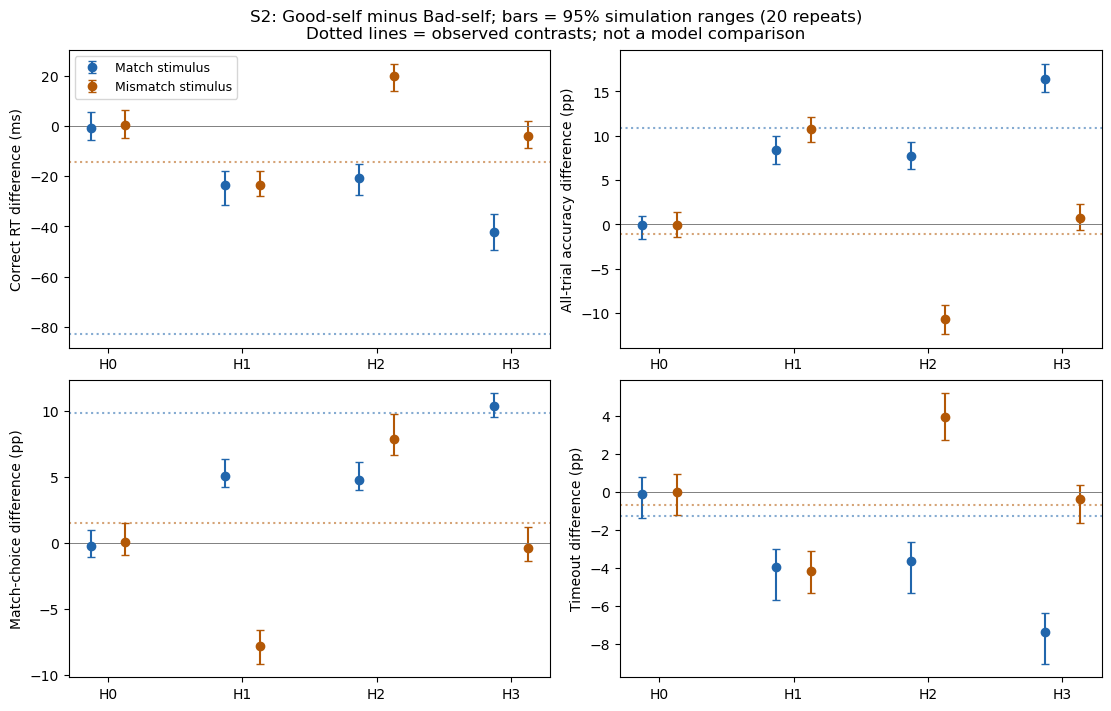

In [4]:
# Good-self minus Bad-self contrasts, not model scores.
metrics=['accuracy_all','accuracy_responded','P_match','timeout','correct_mean','correct_q10','correct_q50','correct_q90','error_q10','error_q50','error_q90']
wide=cells_result.pivot(index=['scenario','model','rep','stim'],columns='condition',values=metrics)
contrasts=pd.DataFrame({m:wide[m]['Good_Self']-wide[m]['Bad_Self'] for m in metrics}).reset_index()
summary=contrasts.groupby(['scenario','model','stim'])[metrics].mean()
display(summary[['accuracy_all','P_match','timeout','correct_mean']].round(5))
display(cells_result.groupby(['scenario','model'])[metrics].mean()[['timeout','correct_mean','error_q90']].round(5))
obs_agg=aggregate(observed)
obs_delta=pd.DataFrame({m:obs_agg[0][m].loc['Good_Self']-obs_agg[0][m].loc['Bad_Self'] for m in metrics})
display(obs_delta[['accuracy_all','P_match','timeout','correct_mean']].rename_axis('Observed stimulus').round(5))
display(cb_result.groupby(['scenario','model']).agg(min_subjects=('n_subjects','min'),smallest_bin_stim_cell=('min_cell_n','min')))

fig,axes=plt.subplots(2,2,figsize=(11,7),constrained_layout=True)
for ax,metric,label,scale in zip(axes.flat,['correct_mean','accuracy_all','P_match','timeout'],
        ['Correct RT difference (ms)','All-trial accuracy difference (pp)','Match-choice difference (pp)','Timeout difference (pp)'],[1000,100,100,100]):
    for s,color,shift in [(1,'#2166ac',-.13),(0,'#b35806',.13)]:
        part=contrasts[(contrasts.scenario=='S2')&(contrasts.stim==s)]
        g=part.groupby('model')[metric]
        means=g.mean().reindex(MODELS)*scale
        lo=g.quantile(.025).reindex(MODELS)*scale; hi=g.quantile(.975).reindex(MODELS)*scale
        ax.errorbar(np.arange(4)+shift,means,yerr=[means-lo,hi-means],fmt='o',color=color,capsize=3,label='Match stimulus' if s else 'Mismatch stimulus')
        ax.axhline(obs_delta.loc[s,metric]*scale,color=color,ls=':',alpha=.55)
    ax.axhline(0,color='grey',lw=.7); ax.set_xticks(range(4),MODELS); ax.set_ylabel(label)
axes[0,0].legend(fontsize=9)
fig.suptitle('S2: Good-self minus Bad-self; bars = 95% simulation ranges (20 repeats)\nDotted lines = observed contrasts; not a model comparison')
plt.show()


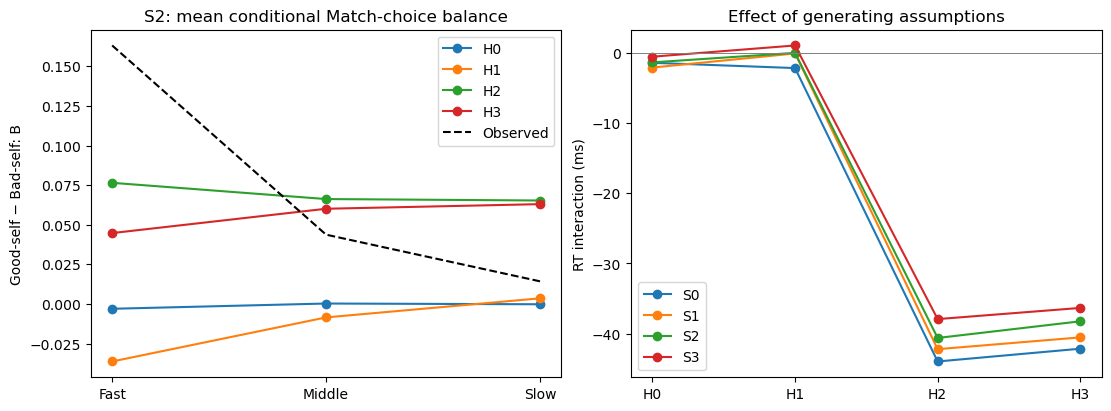

accuracy_all  timeout  correct_mean
model condition  relation                                          
H0    Bad_Other  both                 0.9016   0.0372        0.6885
                 identity_only        0.7834   0.0867        0.7181
                 valence_only         0.8285   0.0657        0.7107
      Bad_Self   both                 0.8756   0.0473        0.6988
                 identity_only        0.7360   0.1022        0.7272
                 valence_only         0.7794   0.0902        0.7199
      Good_Other both                 0.8730   0.0489        0.6989
                 identity_only        0.7284   0.1076        0.7299
                 valence_only         0.7749   0.0872        0.7188
      Good_Self  both                 0.8760   0.0488        0.6976
                 identity_only        0.7309   0.1017        0.7289
                 valence_only         0.7788   0.0897        0.7209
H1    Bad_Other  both                 0.9016   0.0372        0.6885
                 identity_only        0.7834   0.0867        0.7181
                 valence_only         0.8285   0.0657        0.7107
      Bad_Self   both                 0.8234   0.0688        0.7139
                 identity_only        0.6840   0.1188        0.7343
                 valence_only         0.7246   0.1106        0.7286
      Good_Other both                 0.8730   0.0489        0.6989
                 identity_only        0.7284   0.1076        0.7299
                 valence_only         0.7749   0.0872        0.7188
      Good_Self  both                 0.9229   0.0285        0.6792
                 identity_only        0.7914   0.0801        0.7188
                 valence_only         0.8377   0.0654        0.7090
H2    Bad_Other  both                 0.9016   0.0372        0.6885
                 identity_only        0.7834   0.0867        0.7181
                 valence_only         0.8285   0.0657        0.7107
      Bad_Self   both                 0.9076   0.0345        0.6866
                 identity_only        0.7938   0.0816        0.7176
                 valence_only         0.8314   0.0690        0.7099
      Good_Other both                 0.8730   0.0489        0.6989
                 identity_only        0.7284   0.1076        0.7299
                 valence_only         0.7749   0.0872        0.7188
      Good_Self  both                 0.8306   0.0675        0.7084
                 identity_only        0.6662   0.1240        0.7359
                 valence_only         0.7163   0.1122        0.7296
H3    Bad_Other  both                 0.9016   0.0372        0.6885
                 identity_only        0.7834   0.0867        0.7181
                 valence_only         0.8285   0.0657        0.7107
      Bad_Self   both                 0.8650   0.0519        0.7027
                 identity_only        0.7462   0.0985        0.7262
                 valence_only         0.7815   0.0897        0.7197
      Good_Other both                 0.8730   0.0489        0.6989
                 identity_only        0.7284   0.1076        0.7299
                 valence_only         0.7749   0.0872        0.7188
      Good_Self  both                 0.8929   0.0414        0.6907
                 identity_only        0.7308   0.1017        0.7285
                 valence_only         0.7874   0.0860        0.7190

mean      std     MCSE
model stim metric                                       
H0    0    P_match             0.00083  0.00755  0.00169
           accuracy_all       -0.00092  0.00864  0.00193
           accuracy_responded -0.00083  0.00755  0.00169
           correct_mean        0.00042  0.00331  0.00074
           correct_q10        -0.00112  0.00244  0.00054
           correct_q50         0.00024  0.00312  0.00070
           correct_q90         0.00157  0.00976  0.00218
           error_q10          -0.00130  0.00910  0.00204
           error_q50           0.00312  0.01204  0.00269
           error_q90           0.00110  0.01817  0.00406
           timeout             0.00019  0.00672  0.00150
      1    P_match            -0.00218  0.00636  0.00142
           accuracy_all       -0.00108  0.00821  0.00184
           accuracy_responded -0.00218  0.00636  0.00142
           correct_mean       -0.00095  0.00347  0.00078
           correct_q10        -0.00057  0.00196  0.00044
           correct_q50        -0.00115  0.00419  0.00094
           correct_q90        -0.00007  0.00900  0.00201
           error_q10          -0.00412  0.02017  0.00451
           error_q50          -0.00270  0.02291  0.00512
           error_q90           0.00106  0.02340  0.00523
           timeout            -0.00100  0.00651  0.00146
H1    0    P_match            -0.07808  0.00764  0.00171
           accuracy_all        0.10757  0.00983  0.00220
           accuracy_responded  0.07808  0.00764  0.00171
           correct_mean       -0.02359  0.00322  0.00072
           correct_q10        -0.00952  0.00265  0.00059
           correct_q50        -0.02485  0.00333  0.00075
           correct_q90        -0.03685  0.00950  0.00212
           error_q10           0.00655  0.01060  0.00237
           error_q50          -0.01117  0.01539  0.00344
           error_q90          -0.05517  0.02109  0.00472
           timeout            -0.04144  0.00708  0.00158
      1    P_match             0.05047  0.00657  0.00147
           accuracy_all        0.08368  0.00950  0.00212
           accuracy_responded  0.05047  0.00657  0.00147
           correct_mean       -0.02361  0.00401  0.00090
           correct_q10        -0.00619  0.00203  0.00045
           correct_q50        -0.02260  0.00430  0.00096
           correct_q90        -0.04599  0.01031  0.00231
           error_q10           0.00428  0.01260  0.00282
           error_q50          -0.02881  0.01501  0.00336
           error_q90          -0.07734  0.02009  0.00449
           timeout            -0.03921  0.00760  0.00170
H2    0    P_match             0.07921  0.01000  0.00224
           accuracy_all       -0.10624  0.00976  0.00218
           accuracy_responded -0.07921  0.01000  0.00224
           correct_mean        0.01972  0.00314  0.00070
           correct_q10         0.00687  0.00285  0.00064
           correct_q50         0.02062  0.00294  0.00066
           correct_q90         0.03168  0.00827  0.00185
           error_q10          -0.00680  0.00826  0.00185
           error_q50           0.01455  0.01317  0.00295
           error_q90           0.06290  0.01444  0.00323
           timeout             0.03965  0.00665  0.00149
      1    P_match             0.04741  0.00663  0.00148
           accuracy_all        0.07757  0.00942  0.00211
           accuracy_responded  0.04741  0.00663  0.00148
           correct_mean       -0.02090  0.00378  0.00085
           correct_q10        -0.00559  0.00201  0.00045
           correct_q50        -0.02018  0.00427  0.00095
           correct_q90        -0.04003  0.00993  0.00222
           error_q10           0.00365  0.01837  0.00411
           error_q50          -0.02831  0.01836  0.00411
           error_q90          -0.07730  0.01793  0.00401
           timeout            -0.03619  0.00738  0.00165
H3    0    P_match            -0.00372  0.00766  0.00171
           accuracy_all        0.00713  0.00872  0.00195
           accuracy_responded  0.00372  0.00

mean      std
model bin                  
H0    1   -0.00305  0.00769
      2    0.00027  0.00824
      3   -0.00021  0.00760
H1    1   -0.03631  0.00923
      2   -0.00850  0.01113
      3    0.00354  0.00954
H2    1    0.07645  0.00967
      2    0.06620  0.00937
      3    0.06528  0.00971
H3    1    0.04473  0.01120
      2    0.06008  0.01022
      3    0.06298  0.00800

Observed overall timeout rate: 0.025753968253968255
Monte Carlo SE of each repeat-mean estimate = reported SD / sqrt(20).


In [5]:
fig,axes=plt.subplots(1,2,figsize=(11,4),constrained_layout=True)
for model in MODELS:
    b=cb_result[(cb_result.scenario=='S2')&(cb_result.model==model)].pivot(index=['rep','bin'],columns='condition',values='B')
    delta=(b.Good_Self-b.Bad_Self).groupby('bin').mean()
    axes[0].plot(delta.index,delta.values,marker='o',label=model)
observed_b=obs_agg[2].B.unstack('condition')
axes[0].plot(observed_b.index,observed_b.Good_Self-observed_b.Bad_Self,'k--',label='Observed')
axes[0].set(xticks=[1,2,3],xticklabels=['Fast','Middle','Slow'],ylabel='Good-self − Bad-self: B',title='S2: mean conditional Match-choice balance')
axes[0].legend()
for scenario in SCENARIOS:
    q=contrasts[contrasts.scenario.eq(scenario)].groupby(['model','stim']).correct_mean.mean().unstack()
    axes[1].plot(MODELS,(q[1]-q[0]).reindex(MODELS)*1000,marker='o',label=scenario)
axes[1].axhline(0,color='grey',lw=.7)
axes[1].set(ylabel='RT interaction (ms)',title='Effect of generating assumptions')
axes[1].legend()
plt.show()
display(relation_result[relation_result.scenario.eq('S2')].groupby(['model','condition','relation'])[['accuracy_all','timeout','correct_mean']].mean().round(4))
long=contrasts[contrasts.scenario.eq('S2')].melt(id_vars=['model','stim','rep','scenario'],value_vars=metrics,var_name='metric')
lookup=long.groupby(['model','stim','metric']).value.agg(['mean','std'])
lookup['MCSE']=lookup['std']/np.sqrt(REPEATS)
with pd.option_context('display.max_rows',100):
    display(lookup.round(5))
cbwide=cb_result[cb_result.scenario.eq('S2')].pivot(index=['model','rep','bin'],columns='condition',values='B')
display((cbwide.Good_Self-cbwide.Bad_Self).groupby(['model','bin']).agg(['mean','std']).round(5))
print('Observed overall timeout rate:',d.ACC.eq(-1).mean())
print('Monte Carlo SE of each repeat-mean estimate = reported SD / sqrt(20).')


## 解释范围与下一步

四模型之间的预测差异是固定参数约束的后果，不是对真实数据的拟合优度排名。H3 使用了历史 M4 的目标效应，因此即便某些指标更接近观测，也不能据此判定 H3 胜出。S0–S3 比较用于检查结论对生成假设的依赖。

本轮没有估计新的参数、没有模型恢复混淆矩阵，也没有证明 42 名被试足以识别机制。20 次重复的分位范围只作初步描述；尾部范围和接近零的差异应增加重复后再评价。固定个体差异并未覆盖人群抽样变异。无离群、纯超时观察规则与历史 p_outlier=.05 模型并不等价。

进入恢复前仍需固定推断先验、验证截止记录与实验程序的对应关系、确定非法响应和漏按处理，并检查关系难度与 dc 的可替代性。恢复阶段需要按生成模型和效应大小报告参数误差、模型混淆及 H0 被误判为复杂模型的比例，允许不确定分类。

参考：[模型设计与模拟方案](matching_model_design.md)；[前期行为诊断](matching_behavior_review.ipynb)；[Stan Wiener diffusion model](https://mc-stan.org/docs/stan-users-guide/wiener_diffusion_model.html)；[Wilson & Collins (2019)](https://pmc.ncbi.nlm.nih.gov/articles/PMC6879303/)。
